# 1 · Data Cleaning and Feature Extraction

This notebook turns the raw multilingual audiobook clips into a clean, segmented, feature-based dataset.

| Step | What happens |
|---|---|
| **Index & audit** | scan the folders, read container info, find broken / duplicated / mislabelled files |
| **Cleaning** | mono 16 kHz, DC removal + 80 Hz high-pass, pause shortening, loudness normalisation |
| **Segmentation** | each clip → non-overlapping 10 s segments (more training samples, and file-level voting later) |
| **Augmentation** | additive noise, speed perturbation, pitch shift (used **only for training files**) |
| **Features** | 381 features per segment: MFCC/Δ/ΔΔ, SDC, log-mel, spectral, contrast, chroma, ZCR, energy, LPC, F0 / intonation, rhythm |
| **Who is speaking?** | 78 contributors turn out to be only ~24 distinct narrators (shared audiobooks) |
| **Splits** | stratified 80/20 split, contributor-disjoint folds, leave-one-narrator-out groups |

Outputs are written to `data/processed/` and reused by the other notebooks.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, librosa, librosa.display
from slid import config as C, data, cleaning, features, pipeline, plotting
plotting.setup(); C.ensure_dirs()
pd.set_option("display.precision", 3)
FORCE_RECOMPUTE = False   # feature extraction takes ~10 min on 10 CPU cores

## 1.1 Dataset overview

Labels are taken from the folder structure (`Language/Gender`). The ID in each file name belongs to the contributor who cut
the clips from one audiobook; IDs are replaced by anonymous codes `S01…S78`.

In [2]:
meta = data.audit(data.build_index())
print(f"{len(meta)} files · {meta.contributor.nunique()} contributors · {meta.duration.sum()/3600:.1f} h of audio")
summary = meta.groupby(["language", "gender"]).agg(files=("file_id", "size"), contributors=("contributor", "nunique"),
                                                  minutes=("duration", lambda d: d.sum() / 60)).unstack()
summary

720 files · 78 contributors · 12.6 h of audio


files      contributors      minutes         
gender   female male       female male  female     male
language                                               
German       90   90           16   12  90.322   96.679
Italian      90   90           10    8  89.878  114.850
Korean       90   90            7    7  91.312   92.248
Spanish      90   90            9    9  92.642   90.430

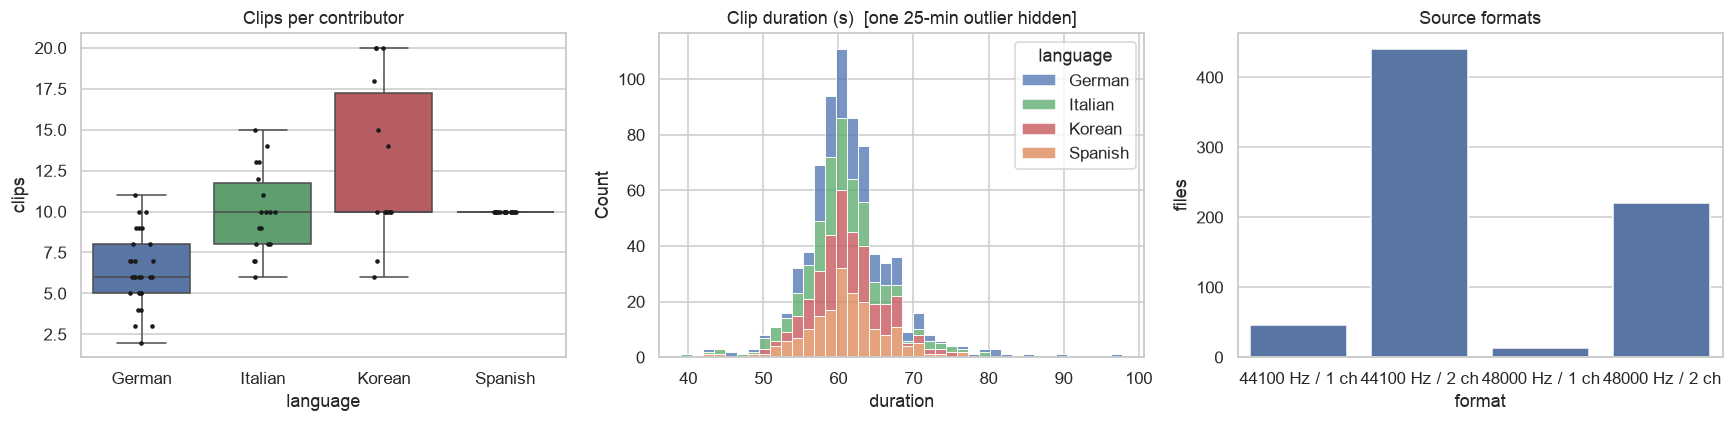

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
spk = meta.groupby(["language", "contributor"]).size().rename("clips").reset_index()
sns.boxplot(data=spk, x="language", y="clips", ax=axes[0], palette=plotting.LANG_COLORS, order=C.LANGUAGES)
sns.stripplot(data=spk, x="language", y="clips", ax=axes[0], color="k", size=3, order=C.LANGUAGES)
axes[0].set_title("Clips per contributor")
sns.histplot(data=meta[meta.duration < 200], x="duration", hue="language", multiple="stack", bins=40,
             palette=plotting.LANG_COLORS, ax=axes[1])
axes[1].set_title("Clip duration (s)  [one 25-min outlier hidden]")
fmt = meta.groupby(["orig_sr", "channels"]).size().rename("files").reset_index()
fmt["format"] = fmt.orig_sr.astype(int).astype(str) + " Hz / " + fmt.channels.astype(int).astype(str) + " ch"
sns.barplot(data=fmt, x="format", y="files", ax=axes[2], color="#4C72B0")
axes[2].set_title("Source formats")
plt.tight_layout(); plotting.save(fig, "01_dataset_overview")

**Observations**

* The dataset is balanced at the language level (180 clips each, 90 male / 90 female), but **not** at the contributor level:
  German has 28 contributors while Korean has only 14. Each contributor provides 2–20 clips.
* Mixed source formats (44.1 / 48 kHz, mono / stereo) → everything is resampled to **16 kHz mono**.
* Clips are ~1 minute long, with one extreme outlier (25 minutes).

## 1.2 Audit: broken, duplicated or inconsistent files

In [4]:
meta["exclude_reason"] = data.flag_exclusions(meta)
checks = pd.Series({
    "unreadable files": meta.read_error.notna().sum(),
    "exact duplicates (md5)": meta.md5.duplicated().sum(),
    "double extension (e.g. .mp3.mp3)": meta.name_has_double_ext.sum(),
    "gender in name ≠ folder": meta.gender_name_mismatch.sum(),
    "language typo in name (koren)": meta.path.str.contains("_koren_").sum(),
    "shorter than 45 s": (meta.duration < 45).sum(),
    "longer than 180 s": (meta.duration > C.MAX_DURATION_SEC).sum(),
}, name="count")
display(checks.to_frame())
display(meta.loc[meta.exclude_reason != "", ["file_id", "language", "gender", "duration", "exclude_reason"]])

,count
unreadable files,0
exact duplicates (md5),0
double extension (e.g. .mp3.mp3),31
gender in name ≠ folder,0
language typo in name (koren),10
shorter than 45 s,7
longer than 180 s,1


,file_id,language,gender,duration,exclude_reason
337,ITA_M_S51_337,Italian,male,1537.769,full-source upload (overlaps other clips)


* No corrupt files and no exact duplicates.
* File-name problems (double extensions, a language typo) are harmless because labels come from folders.
* One Italian file is a **25-minute upload of the whole source**; the same contributor's other clips are cut from it, so keeping it
  would duplicate content (and leak between train and test). It is excluded.

In [5]:
meta = meta[meta.exclude_reason == ""].reset_index(drop=True)
print(len(meta), "files kept")

719 files kept


## 1.3 Cleaning

Audiobook recordings are already fairly clean, so the goal is **consistency** rather than heavy denoising
(aggressive denoising can remove language cues and add artefacts):

1. **Resample to 16 kHz mono** – the speech band lies below 8 kHz; one sample rate makes features comparable.
2. **DC removal + 4th-order 80 Hz high-pass** – removes rumble and hum below the voice range.
3. **Pause shortening** – regions 35 dB below the peak are silence; pauses longer than 0.3 s are cut to 0.3 s.
   Short pauses are kept because pause patterns are part of a language's rhythm.
4. **Loudness normalisation** – active speech is scaled to −23 dBFS RMS, then peak-limited, so recording gain does not
   become a feature.

Example before/after on one clip:

,raw_duration,clipping_ratio,speech_ratio,snr_db,n_long_pauses,clean_duration
value,56.804,0.0,0.698,39.686,15.0,45.908


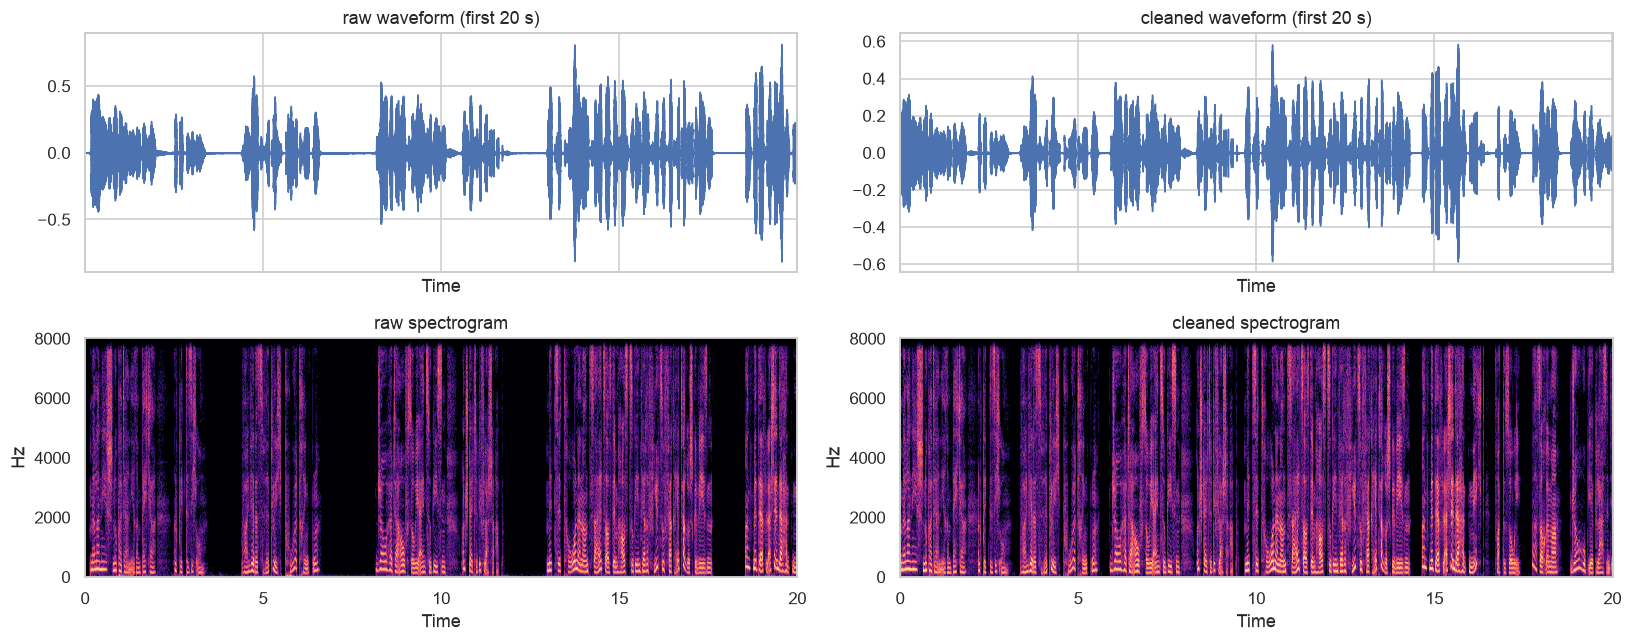

In [6]:
ex = meta.iloc[0]
y_raw = cleaning.load(ex.path)
y_cln, info = cleaning.clean(y_raw)
fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharex="col")
for col, (y, name) in enumerate([(y_raw, "raw"), (y_cln, "cleaned")]):
    librosa.display.waveshow(y[: 20 * C.SR], sr=C.SR, ax=axes[0, col], color="#4C72B0")
    axes[0, col].set_title(f"{name} waveform (first 20 s)")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y[: 20 * C.SR], n_fft=C.N_FFT, hop_length=C.HOP_LENGTH)), ref=np.max)
    librosa.display.specshow(S, sr=C.SR, hop_length=C.HOP_LENGTH, x_axis="time", y_axis="hz", ax=axes[1, col], cmap="magma")
    axes[1, col].set_title(f"{name} spectrogram")
plt.tight_layout(); plotting.save(fig, "01_cleaning_example")
pd.Series(info).to_frame("value").T

## 1.4 Augmentation

Three label-preserving transformations simulate variability the model will meet on new speakers and recordings:

| Augmentation | Simulates | Detail |
|---|---|---|
| `noise` | poorer recording conditions | pink (1/f) noise at a random SNR of 10–20 dB |
| `speed` | speaking rate + voice differences | resampling by ×0.9 or ×1.1 (Kaldi-style speed perturbation) |
| `pitch` | different speakers | pitch shift of ±1–3 semitones, tempo unchanged |

Augmented copies are generated for every file, but **only copies of training files are ever used for training**;
test files are always evaluated on their original audio.

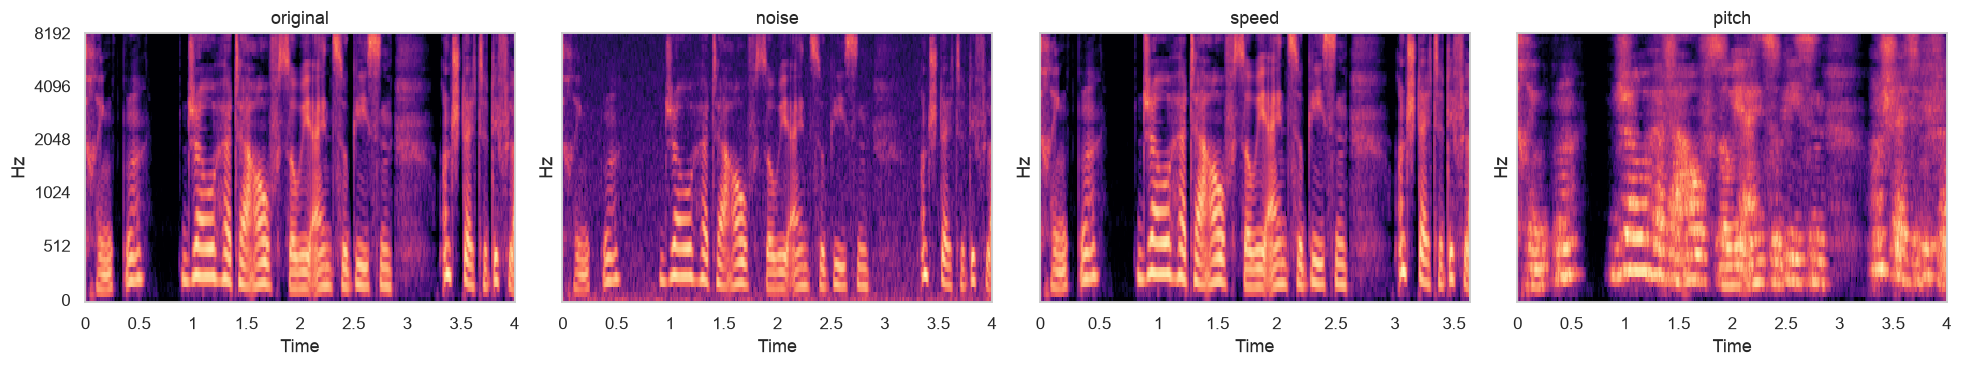

In [7]:
excerpt = y_cln[5 * C.SR: 9 * C.SR]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
for ax, kind in zip(axes, ["original", *pipeline.AUG_KINDS]):
    y = excerpt if kind == "original" else cleaning.augment(excerpt, kind, seed=0)
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=C.SR, n_fft=C.N_FFT, hop_length=C.HOP_LENGTH, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=C.SR, hop_length=C.HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax, cmap="magma")
    ax.set_title(kind)
plt.tight_layout(); plotting.save(fig, "01_augmentation_examples")

## 1.5 Segmentation and feature extraction

Each cleaned clip is cut into **non-overlapping 10 s segments** (a tail of ≥ 5 s is kept). This multiplies the number of
samples and lets us make a file-level decision later by averaging segment probabilities.

Features (one vector per segment, statistics over 25 ms frames with a 10 ms hop):

| Group | Dim | Why it can separate languages |
|---|---|---|
| `mfcc` (MFCC + Δ + ΔΔ, mean/std) | 120 | spectral envelope → which phonemes / vowels occur and how fast they change |
| `sdc` (shifted delta cepstra 7-1-3-7) | 98 | stacks deltas over ~0.2 s → captures phone *sequences*; the classic acoustic LID feature |
| `mel` (40 log-mel bands) | 80 | raw spectral energy distribution (e.g. fricative-rich languages) |
| `spec` (centroid, bandwidth, roll-off, flatness) | 8 | brightness / noisiness of the sound inventory |
| `contrast` | 14 | harmonic peaks vs valleys per sub-band (vowel vs consonant balance) |
| `chroma` | 24 | pitch-class energy; mostly music-oriented, included as a weak baseline |
| `zcr`, `rms` | 4 | voiced/unvoiced balance and energy dynamics |
| `lpc` (order 12) | 12 | all-pole vocal-tract model (formant structure) |
| `f0` (pYIN, in semitones re. speaker median) | 7 | intonation range and movement, normalised to remove the speaker's own pitch level |
| `rhythm` | 14 | modulation spectrum of the energy envelope (syllable rate ≈ 3–6 Hz), onset rate, nPVI, pause ratio – stress- vs syllable-timed rhythm |

PLP was considered but omitted: it is very close to MFCC in information content, and SDC adds more for LID.

In [8]:
feat_path = C.PROCESSED_DIR / "segment_features.parquet"
report_path = C.PROCESSED_DIR / "cleaning_report.parquet"
if FORCE_RECOMPUTE or not feat_path.exists():
    clean_report, seg = pipeline.run(meta, n_jobs=-1, augment=True)
    seg.to_parquet(feat_path); clean_report.to_parquet(report_path)
else:
    seg, clean_report = pd.read_parquet(feat_path), pd.read_parquet(report_path)
feat_cols = features.feature_columns(seg.columns)
print(f"{len(seg)} segment rows × {len(feat_cols)} features")
seg.groupby("aug").size().rename("segments").to_frame().T

15683 segment rows × 381 features


aug,noise,none,pitch,speed
segments,3920,3920,3920,3923


In [9]:
groups = pd.Series([c.split("_")[0] for c in feat_cols]).value_counts().reindex(features.FEATURE_GROUPS)
pd.DataFrame({"dims": groups, "description": pd.Series(features.FEATURE_GROUPS)})

,dims,description
mfcc,120,MFCC + delta + delta-delta (spectral envelope ...
sdc,98,Shifted Delta Cepstra 7-1-3-7 (longer-range ph...
mel,80,Log-mel band energies
spec,8,"Spectral centroid, bandwidth, roll-off, flatness"
contrast,14,Spectral contrast (peak vs valley per sub-band)
chroma,24,Chroma (pitch-class energy)
zcr,2,Zero-crossing rate
rms,2,Frame energy
lpc,12,Linear Predictive Coding coefficients (vocal-t...
f0,7,Fundamental frequency / intonation (speaker-no...


### Cleaning report

,raw_duration,clean_duration,speech_ratio,snr_db,n_long_pauses,clipping_ratio
language,,,,,,
German,61.137,53.666,0.748,36.707,15.5,0.0
Italian,59.797,56.400,0.844,43.631,12.0,0.0
Korean,60.725,49.586,0.706,40.107,18.0,0.0
Spanish,60.985,55.850,0.816,33.555,15.0,0.0


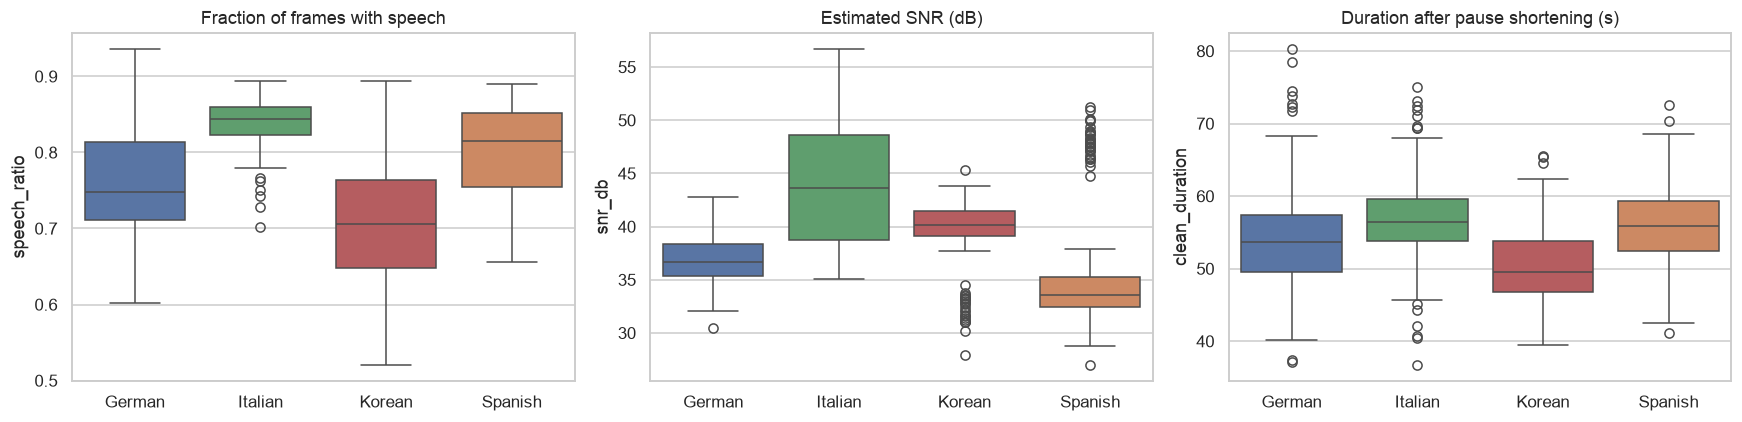

In [10]:
rep = clean_report.merge(meta[["file_id", "language"]], on="file_id")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["speech_ratio", "snr_db", "clean_duration"],
                          ["Fraction of frames with speech", "Estimated SNR (dB)", "Duration after pause shortening (s)"]):
    sns.boxplot(data=rep, x="language", y=col, ax=ax, palette=plotting.LANG_COLORS, order=C.LANGUAGES)
    ax.set_title(title); ax.set_xlabel("")
plt.tight_layout(); plotting.save(fig, "01_cleaning_report")
rep.groupby("language")[["raw_duration", "clean_duration", "speech_ratio", "snr_db", "n_long_pauses", "clipping_ratio"]].median()

Pause shortening removes 5–18 % of each clip (most for Korean, least for Italian). The SNR estimates are high (≈ 34–44 dB,
studio audiobook recordings), which supports the decision not to apply spectral denoising. Recording conditions still differ
between languages and narrators, which is a reminder that a model could partly learn the *channel* rather than the
*language* — this is tested in the next section and with narrator-disjoint evaluation.

## 1.6 Contributors are not narrators

Each contributor cut clips from a single audiobook, but **several contributors used the same
audiobook** (different time ranges). The contributor code is therefore not a speaker ID. If two contributors share a
narrator, a "contributor-disjoint" split still has the same voice and recording in train and test.

Two checks on file-level feature vectors (mean of segment features, standardised):

1. **Can a classifier tell contributors apart?** If every contributor had a unique narrator, this should be easy.
2. **Distance ratio** for each pair of contributors (same language and gender): mean distance between their clips divided
   by the typical distance *within* each contributor. A ratio ≈ 1 means the two sets of clips are as similar as clips from
   one recording → most likely the same narrator and audiobook.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from slid import clustering
Ffile = clustering.file_level_matrix(seg, feat_cols).loc[meta.file_id]
Zfile = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Ffile))
many = meta.contributor.map(meta.contributor.value_counts()).to_numpy() >= 3
pred = cross_val_predict(LogisticRegression(C=0.1, max_iter=3000), Zfile[many], meta.contributor[many],
                         cv=StratifiedKFold(3, shuffle=True, random_state=C.RANDOM_STATE))
print(f"contributor identification accuracy: {np.mean(pred == meta.contributor[many]):.1%} "
      f"({meta.contributor[many].nunique()} contributors; language identification on the same features is ~99%)")

contributor identification accuracy: 67.9% (77 contributors; language identification on the same features is ~99%)


contributors  narrators
language gender                         
German   female            16          3
         male              12          2
Italian  female            10          2
         male               8          7
Korean   female             7          3
         male               7          2
Spanish  female             9          3
         male               9          2
all                        78         24

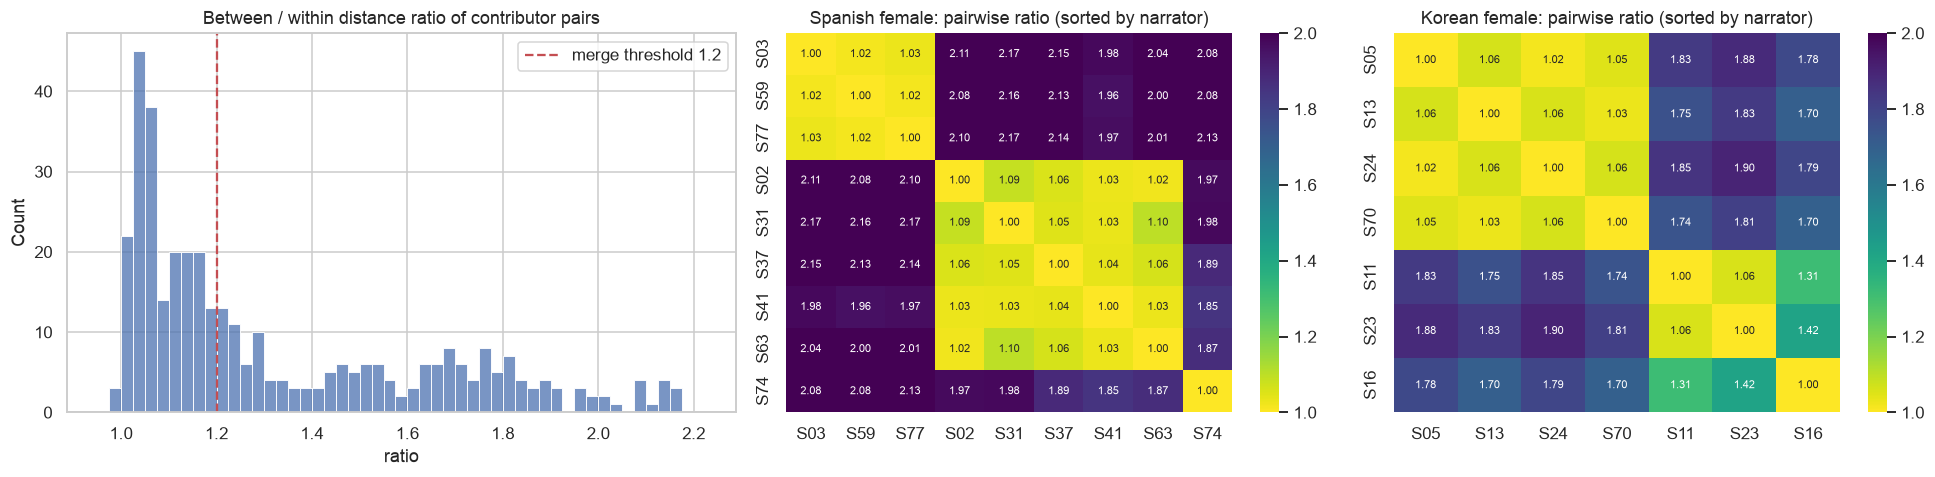

In [12]:
ratios = data.contributor_distance_ratios(Zfile, meta.reset_index(drop=True))
narr = data.estimate_narrators(ratios, meta, cut=1.2)
meta["narrator"] = meta.contributor.map(narr)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
sns.histplot(ratios.ratio, bins=np.arange(0.95, 2.25, 0.025), ax=axes[0], color="#4C72B0")
axes[0].axvline(1.2, ls="--", c="C3", label="merge threshold 1.2"); axes[0].legend()
axes[0].set_title("Between / within distance ratio of contributor pairs"); axes[0].set_xlabel("ratio")
for ax, (lang, gender) in zip(axes[1:], [("Spanish", "female"), ("Korean", "female")]):
    sub = ratios[(ratios.language == lang) & (ratios.gender == gender)]
    names = sorted(set(sub.a) | set(sub.b))
    M = pd.DataFrame(1.0, index=names, columns=names)
    for a, b, r in zip(sub.a, sub.b, sub.ratio):
        M.loc[a, b] = M.loc[b, a] = r
    order = meta.drop_duplicates("contributor").set_index("contributor").loc[names].sort_values("narrator").index
    sns.heatmap(M.loc[order, order], cmap="viridis_r", vmin=1, vmax=2, ax=ax, annot=True, fmt=".2f", annot_kws={"size": 7})
    ax.set_title(f"{lang} {gender}: pairwise ratio (sorted by narrator)")
plt.tight_layout(); plotting.save(fig, "01_contributors_vs_narrators")

tbl = meta.groupby(["language", "gender"]).agg(contributors=("contributor", "nunique"), narrators=("narrator", "nunique"))
tbl.loc[("all", ""), :] = [meta.contributor.nunique(), meta.narrator.nunique()]
tbl

The contributor classifier is far from perfect, and many pairs have a ratio barely above 1.0. Where the distribution has a
gap (e.g. Spanish female: ≤ 1.10 vs ≥ 1.85; Korean female: ≤ 1.06 vs ≥ 1.31) it separates *same* from *different*
recordings, so contributors are merged by average linkage at a ratio of **1.2**.

Result: the 78 contributors correspond to only **~24 estimated narrators**, mostly 2–3 per language and gender.
This is an estimate from audio alone (a list of which audiobook each contributor used would give the exact grouping),
but it is decisive for evaluation: any split that does not keep narrators apart lets the model recognise the *voice and
recording* instead of the *language*.

## 1.7 Train / test splits

| Protocol | Grouping | Question it answers |
|---|---|---|
| **Random 80/20** (standard) | file-level, stratified by language × gender | how well are *new clips of known narrators* classified? |
| **Contributor-disjoint 5-fold** | `StratifiedGroupKFold` on contributor | what most people would call "speaker-independent" |
| **Leave-one-narrator-out** | one estimated narrator held out at a time | how well does it work for a *voice it has never heard*? |

In every protocol all segments and augmented copies of a file stay on the same side.

In [13]:
meta["split"] = data.make_split(meta)
meta["contributor_fold"] = data.group_folds(meta, "contributor")
display(pd.crosstab(meta.language, meta.split, margins=True))
for g in ["contributor", "narrator"]:
    shared = set(meta[meta.split == "train"][g]) & set(meta[meta.split == "test"][g])
    print(f"{g}s present in both random-split train and test: {len(shared)} / {meta[g].nunique()}")
fold_narr = meta.groupby("narrator").contributor_fold.nunique()
print(f"narrators spread over more than one contributor fold: {(fold_narr > 1).sum()} / {len(fold_narr)}")
display(meta.groupby(["language", "gender", "narrator"]).size().unstack(["language", "gender"]).fillna(0).astype(int).T)
meta.drop(columns=["md5", "read_error", "name_gender"]).to_parquet(C.PROCESSED_DIR / "metadata.parquet")

split,test,train,All
language,,,
German,36,144,180
Italian,36,143,179
Korean,36,144,180
Spanish,36,144,180
All,144,575,719


contributors present in both random-split train and test: 62 / 78
narrators present in both random-split train and test: 22 / 24
narrators spread over more than one contributor fold: 13 / 24


narrator         N01  N02  N03  N04  N05  N06  N07  N08  N09  N10  ...  N15  \
language gender                                                    ...        
German   female   47   40    3    0    0    0    0    0    0    0  ...    0   
         male      0    0    0   44   46    0    0    0    0    0  ...    0   
Italian  female    0    0    0    0    0   80   10    0    0    0  ...    0   
         male      0    0    0    0    0    0    0   14   14   12  ...    0   
Korean   female    0    0    0    0    0    0    0    0    0    0  ...   60   
         male      0    0    0    0    0    0    0    0    0    0  ...    0   
Spanish  female    0    0    0    0    0    0    0    0    0    0  ...    0   
         male      0    0    0    0    0    0    0    0    0    0  ...    0   

narrator         N16  N17  N18  N19  N20  N21  N22  N23  N24  
language gender                                               
German   female    0    0    0    0    0    0    0    0    0  
         male      0    0    0    0    0    0    0    0    0  
Italian  female    0    0    0    0    0    0    0    0    0  
         male      0    0    0    0    0    0    0    0    0  
Korean   female   20   10    0    0    0    0    0    0    0  
         male      0    0   70   20    0    0    0    0    0  
Spanish  female    0    0    0    0   30   50   10    0    0  
         male      0    0    0    0    0    0    0   80   10  

[8 rows x 24 columns]

## 1.8 Which features look discriminative?

A first look (training files only, original audio): the ANOVA F-statistic of each feature across the four languages,
averaged per group, and a few interpretable features.

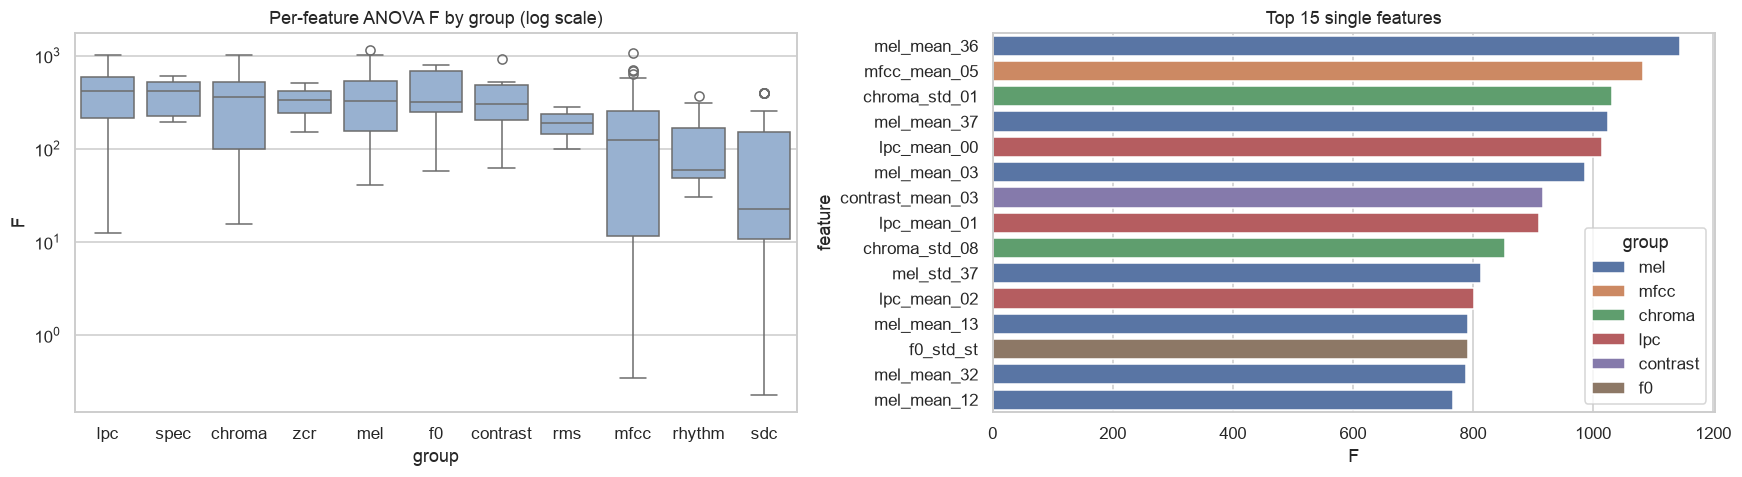

In [14]:
from sklearn.feature_selection import f_classif
tr = seg[(seg.aug == "none")].merge(meta[["file_id", "language", "label", "split"]], on="file_id")
tr = tr[tr.split == "train"]
X = tr[feat_cols].fillna(tr[feat_cols].median())
F, _ = f_classif(X, tr.label)
fstat = pd.DataFrame({"feature": feat_cols, "F": F, "group": [c.split("_")[0] for c in feat_cols]})
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
order = fstat.groupby("group").F.median().sort_values(ascending=False).index
sns.boxplot(data=fstat, x="group", y="F", order=order, ax=axes[0], color="#8fb0d9")
axes[0].set_yscale("log"); axes[0].set_title("Per-feature ANOVA F by group (log scale)")
top = fstat.nlargest(15, "F")
sns.barplot(data=top, y="feature", x="F", hue="group", dodge=False, ax=axes[1])
axes[1].set_title("Top 15 single features")
plt.tight_layout(); plotting.save(fig, "01_feature_anova")

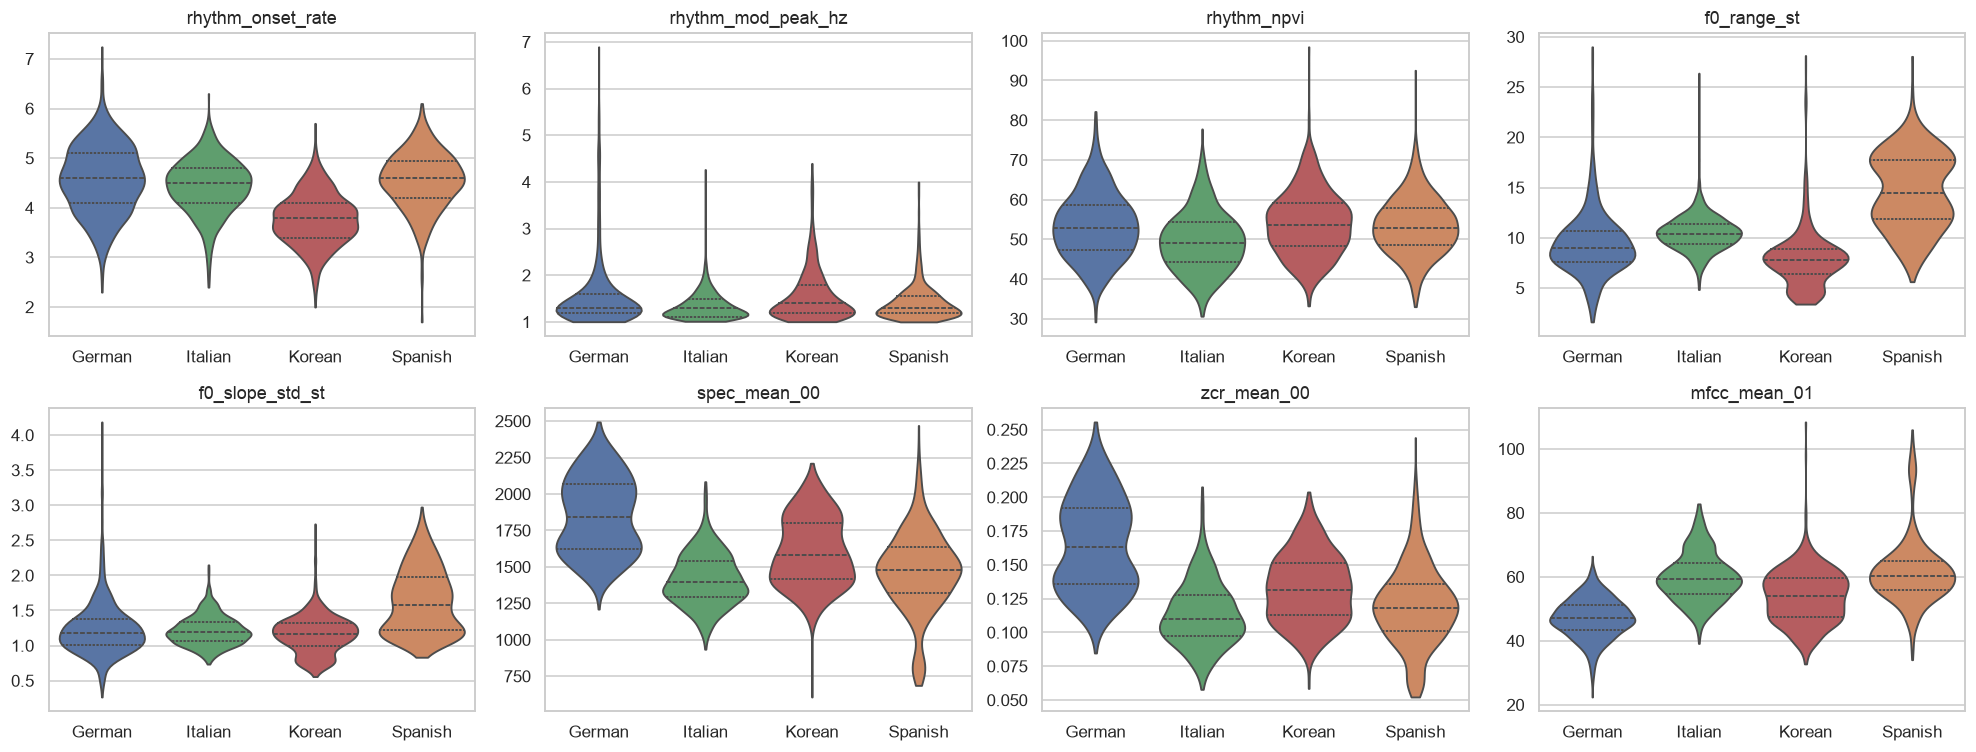

In [15]:
show = ["rhythm_onset_rate", "rhythm_mod_peak_hz", "rhythm_npvi", "f0_range_st", "f0_slope_std_st", "spec_mean_00", "zcr_mean_00", "mfcc_mean_01"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, show):
    sns.violinplot(data=tr, x="language", y=col, ax=ax, palette=plotting.LANG_COLORS, order=C.LANGUAGES, cut=0, inner="quartile")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plotting.save(fig, "01_feature_distributions")

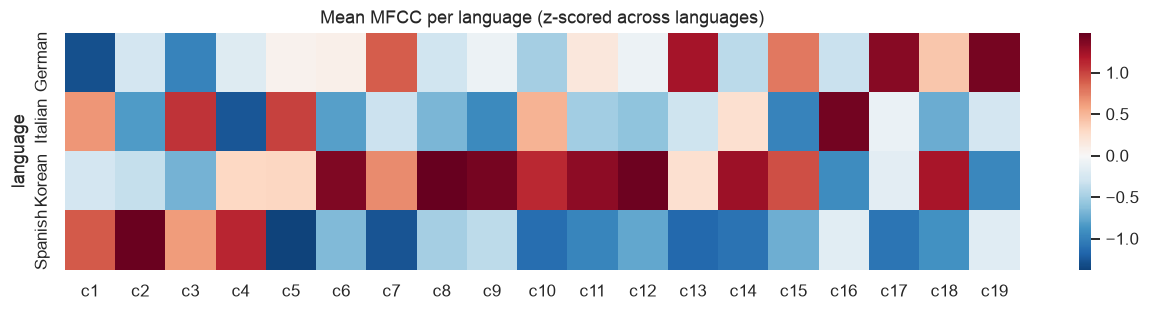

In [16]:
mf = tr.groupby("language")[[f"mfcc_mean_{i:02d}" for i in range(1, C.N_MFCC)]].mean()
mf = (mf - mf.mean()) / mf.std()
fig, ax = plt.subplots(figsize=(14, 2.8))
sns.heatmap(mf, cmap="RdBu_r", center=0, ax=ax, xticklabels=[f"c{i}" for i in range(1, C.N_MFCC)])
ax.set_title("Mean MFCC per language (z-scored across languages)"); plotting.save(fig, "01_mfcc_profile")

**Take-aways**

* Several features differ clearly between languages, and the differences match linguistic intuition:
  * **Korean** has the lowest onset rate (≈ 3.8 vs ≈ 4.5 events/s) – fewer, longer syllable-like units in this sample.
  * **Spanish** narrators use the widest intonation range and the most pitch movement (`f0_range_st`, `f0_slope_std_st`),
    even after normalising each narrator to their own median pitch.
  * **German** has the highest spectral centroid and zero-crossing rate – consistent with its many fricatives and
    consonant clusters.
* Static spectral statistics (`mel`, `lpc`, `spec`, `contrast`) have the highest single-feature F values. Dynamic features
  (MFCC deltas, `sdc`) are weak *one at a time*: their means are close to zero for every language, and their information
  is in combinations, which only a multivariate model can use.
* `chroma` scores surprisingly high. Chroma is designed for music, so this most likely reflects narrator- and
  recording-specific pitch/timbre rather than language. With only ~6 narrators per language and many segments per
  narrator, univariate statistics mix *narrator* and *language* effects; the ablations in notebook 4 test which groups
  still help on unseen narrators.
* `rhythm_mod_peak_hz` peaks at ~1 Hz (phrase level) for all languages and is not informative on its own.

All features are kept; scaling, PCA/LDA and model choice are handled in the next notebook.